# Setup and Data Preprocessing

This notebook sets up the workspace and walks through the first step of any machine learning project: getting the data into a clean, usable table. We load a small file, inspect it, handle missing values, encode a categorical column, and split the data into features and target.

## Imports and a helper to load the datasets

In [1]:
# Standard imports for the whole course
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Find the Datasets folder whether the notebook is run from the
# project root or from inside the notebooks folder.
from pathlib import Path
for candidate in [Path("Datasets"), Path("../Datasets")]:
    if candidate.exists():
        DATA = candidate
        break

def load(name):
    """Load a CSV from the Datasets folder by file name."""
    return pd.read_csv(DATA / name)

print("Datasets are in:", DATA.resolve())
print(sorted(p.name for p in DATA.glob("*.csv")))

Datasets are in: /home/kutt/Downloads/temp/ML/Machine_Learning/Datasets
['Data_2.csv', 'Linear_Regression_Salary_Data.csv', 'Linear_Regression_WeatherData.csv', 'Logistic_Regression_pima-indians-diabetes.csv', 'Logistic_Regression_weatherAlbury.csv', 'Mall_Customers_Clustering.csv', 'Multiple_Linear_Regression_50_CompList.csv', 'Multiple_Linear_Regression_WeatherDataM.csv', 'Naive_Bayes_Decision_RF_Tree_Boosting_User_Data.csv', 'PCA_Wine.csv', 'Polynomial_Regression_Position_Salaries.csv', 'Polynomial_Regression_WeatherDataP.csv']


## Loading a dataset

The small `Data_2.csv` records a country, age, and salary for each customer, and whether they purchased. We print the whole table with `to_string()` so that nothing is hidden.

In [2]:
df = load("Data_2.csv")
print(df.to_string())

   Country   Age   Salary Purchased
0   France  44.0  72000.0        No
1    Spain  27.0  48000.0       Yes
2  Germany  30.0  54000.0        No
3    Spain  38.0  61000.0        No
4  Germany  40.0      NaN       Yes
5   France  35.0  58000.0       Yes
6    Spain   NaN  52000.0        No
7   France  48.0  79000.0       Yes
8  Germany  50.0  83000.0        No
9   France  37.0  67000.0       Yes


## Finding missing values

`isna()` marks every empty cell, and summing the columns counts them per column.

In [3]:
df.isna().sum()

Country      0
Age          1
Salary       1
Purchased    0
dtype: int64

## Filling missing values

We fill the numeric gaps with the column mean. This is the simplest form of imputation.

In [4]:
df["Age"] = df["Age"].fillna(df["Age"].mean())
df["Salary"] = df["Salary"].fillna(df["Salary"].mean())
print(df.isna().sum())

Country      0
Age          0
Salary       0
Purchased    0
dtype: int64


## Encoding a categorical column

Country is text, so we turn it into numbers two ways. Label encoding gives each country an integer. One hot encoding gives each country its own 0/1 column, which avoids implying a false order.

In [5]:
labelled = df.copy()
labelled["Country_encoded"] = pd.factorize(labelled["Country"])[0]
print(labelled[["Country", "Country_encoded"]].drop_duplicates())

onehot = pd.get_dummies(df, columns=["Country"])
print(onehot.head())

   Country  Country_encoded
0   France                0
1    Spain                1
2  Germany                2
    Age        Salary Purchased  Country_France  Country_Germany  \
0  44.0  72000.000000        No            True            False   
1  27.0  48000.000000       Yes           False            False   
2  30.0  54000.000000        No           False             True   
3  38.0  61000.000000        No           False            False   
4  40.0  63777.777778       Yes           False             True   

   Country_Spain  
0          False  
1           True  
2          False  
3           True  
4          False  


## Separating features from the target

The target is the column we want to predict, and the features are everything we predict from. A feature matrix is always two dimensional.

In [6]:
X = df[["Country", "Age", "Salary"]].values
y = df["Purchased"].values
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10, 3)
y shape: (10,)


## Splitting into training and test sets

We hold back part of the data so we can measure how the model behaves on rows it has never seen.

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0)
print(X_train.shape, X_test.shape)

(8, 3) (2, 3)


## Feature scaling

Age and salary sit on very different scales. The three common scalings are shown on the same small feature.

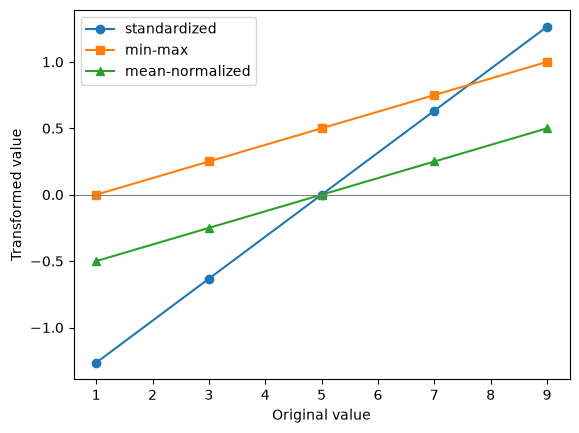

In [8]:
f = pd.Series([1, 3, 5, 7, 9], dtype=float)
standardized = (f - f.mean()) / f.std()
minmax = (f - f.min()) / (f.max() - f.min())
mean_norm = (f - f.mean()) / (f.max() - f.min())

plt.plot(f, standardized, "o-", label="standardized")
plt.plot(f, minmax, "s-", label="min-max")
plt.plot(f, mean_norm, "^-", label="mean-normalized")
plt.axhline(0, color="gray", lw=0.8)
plt.xlabel("Original value"); plt.ylabel("Transformed value")
plt.legend(); plt.show()